# Extended Analysis mbedTLS

In [1]:
import trsfile
import matplotlib.pyplot as plt
import numpy as np
from tqdm import trange, tqdm
import seaborn as sns
import bokeh.plotting as bk
import lpips
import librosa
import torchaudio
import torch
import time
import math

from skimage.metrics import structural_similarity as ssim
import torch
import torch.nn.functional as F
import numpy as np

from bokeh.io import output_notebook 
output_notebook()


from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_squared_error


Loading BokehJS ...

In [2]:
def compute_correlation(target_trace, template_trace):
    corr = np.corrcoef(target_trace, template_trace)[0,1] # Take the non-identity part of the correlation matrix. Note that [0,1] = [1,0]
    return np.abs(corr)

In [3]:
def plot_similarity(similarity_array0, similarity_array1, iteration, similarity_function, leakage):
        plt.figure(figsize=(10,5))
        plt.plot(similarity_array0, label = "bit 0")
        plt.plot(similarity_array1, label = "bit 1")
        plt.title("Similarity for template 2P and 3P on {}".format(similarity_function.__name__))
        plt.xlabel("Timesamples")
        plt.ylabel("Delta power consumption")
        plt.legend()
      #  plt.savefig("./ota2_{}_scalar1{}_{}.png".format(leakage, iteration, similarity_function.__name__), bbox_inches='tight')
        plt.show()

def pattern_match(target_trace, template_trace, comparison_function, poi_start, poi_end, step=1):
    comparison_array = []
    window = poi_end - poi_start
    template_trace_sliced = template_trace[poi_start:poi_end]
    for timesample in trange(0, len(target_trace) - window, step):
        comparison = comparison_function(target_trace[timesample:timesample + window], template_trace_sliced)
        comparison_array.append(comparison)
    return np.array(comparison_array)

def determine_keybit(comparison_array0, comparison_array1, sign):
    # Get the highest peak of both, and take that timesample as comparison point
    if sign == "max":
        peak0 = np.max(comparison_array0)
        peak1 = np.max(comparison_array1)
        keybit_guess = np.argmax([peak0, peak1]) 
    elif sign == "min":
        peak0 = np.min(comparison_array0)
        peak1 = np.min(comparison_array1)
        keybit_guess = np.argmin([peak0, peak1]) 
    
    return int(keybit_guess)

In [4]:
def open_trs_and_average(path):
    with trsfile.open(path, 'r') as traces:
    # Show all headers

        for header, value in traces.get_headers().items():
            print(header, '=', value)

            if str(header) == "Header.NUMBER_TRACES":
                nr_traces = value
            elif str(header) == "Header.NUMBER_SAMPLES":
                nr_samples = value
        print()

        trace_array = np.zeros((nr_traces, nr_samples))
            
        # Iterate over the trace
        for i, trace in enumerate(traces):
            print('Trace {0:d} contains {1:d} samples'.format(i, len(trace)))
            print('  - minimum value in trace: {0:f}'.format(min(trace)))
            print('  - maximum value in trace: {0:f}'.format(max(trace)))
            trace_array[i,:] = trace
        
        return np.mean(trace_array, axis=0)


## Load in datasets

In [5]:
## Scalar  = 2 => 10 in binary
single_target_trace_sc2 = np.array(trsfile.open("../../datasets/ota2/P1_scalar2_unprotected_ec_scalmul.trs", 'r')[0], dtype=np.float64)
single_template_2P_sc2 = np.array(trsfile.open('../../datasets/ota2/2P1_scalar2_unprotected_ec_scalmul.trs', 'r')[0], dtype=np.float64)
single_template_3P_sc2 = np.array(trsfile.open('../../datasets/ota2/3P1_scalar2_unprotected_ec_scalmul.trs', 'r')[0], dtype=np.float64)

## Scalar  = 3 => 11 in binary
single_target_trace_sc3 = np.array(trsfile.open("../../datasets/ota2/P1_scalar3_unprotected_ec_scalmul.trs", 'r')[0], dtype = np.float64)
single_template_2P_sc3 = np.array(trsfile.open('../../datasets/ota2/2P1_scalar3_unprotected_ec_scalmul.trs', 'r')[0], dtype = np.float64)
single_template_3P_sc3 = np.array(trsfile.open('../../datasets/ota2/3P1_scalar3_unprotected_ec_scalmul.trs', 'r')[0], dtype = np.float64)




In [6]:
single_trace_leakage_sc2 = [single_target_trace_sc2, single_template_2P_sc2, single_template_3P_sc2]
single_trace_leakage_sc3 = [single_target_trace_sc3, single_template_2P_sc3, single_template_3P_sc3]

## Similarity based attacks on vertical leakage

In [7]:
def calc_spectrogram(trace, n_fft = 512): #NOTE: it is very sensitive for this value
    trace_tensor = torch.tensor(trace, dtype=torch.float32)
    spec = torchaudio.transforms.Spectrogram(n_fft=n_fft)(trace_tensor)
    spec_db = librosa.power_to_db(spec.numpy(), ref=np.max)

    # Normalize to [0,1]
    spec_db = (spec_db - spec_db.min()) / (spec_db.max() - spec_db.min() + 1e-8)

    return spec_db

def spec_to_tensor(spec_db, target_size):
    # Convert to 3-channel float32 tensor for LPIPS: (C, H, W)
    spec_tensor = torch.tensor(spec_db).unsqueeze(0).unsqueeze(0)  # (1,1,H,W)
    # Resize to target_size
    spec_resized = F.interpolate(spec_tensor, size=target_size, mode='bilinear', align_corners=False)

    return spec_resized

In [8]:
## LPIPS model
device = "cuda" if torch.cuda.is_available() else "cpu"
lpips_model = lpips.LPIPS(net='alex')
lpips_model.eval()
lpips_model.to(device)


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/home/lizzy/.local/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/lizzy/.local/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /home/lizzy/.local/lib/python3.10/site-packages/lpips/weights/v0.1/alex.pth


LPIPS(
  (scaling_layer): ScalingLayer()
  (net): alexnet(
    (slice1): Sequential(
      (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
      (1): ReLU(inplace=True)
    )
    (slice2): Sequential(
      (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): ReLU(inplace=True)
    )
    (slice3): Sequential(
      (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
      (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (7): ReLU(inplace=True)
    )
    (slice4): Sequential(
      (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (9): ReLU(inplace=True)
    )
    (slice5): Sequential(
      (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (11): ReLU(inplace=True)
    )
  )
  (lin0): NetLinLayer(
    (model): Sequential(
      (0): D

In [9]:
def compute_distance_lpips(target_trace, template_trace):
    tensor_size = (224, 224)  # LPIPS expects 224x224 input
    
    target_spec  = calc_spectrogram(target_trace, 512)
    template_spec = calc_spectrogram(template_trace, 512)

    target_tensor = spec_to_tensor(target_spec, tensor_size).to(device)
    template_tensor = spec_to_tensor(template_spec, tensor_size).to(device)

    d = lpips_model.forward(target_tensor,template_tensor)
    return d.detach().cpu().numpy().ravel()[0]

def compute_structural_similarity(target_trace, template_trace):
    """Compute structural similarity between two traces."""
    target_tensor = calc_spectrogram(target_trace, 512)
    template_tensor = calc_spectrogram(template_trace, 512)

    return ssim(target_tensor, template_tensor, data_range=target_tensor.max() - target_tensor.min())

def compute_cosine(x, y):
    x = calc_spectrogram(x, 512)
    y = calc_spectrogram(y, 512)
    return cosine_similarity(x, y)[0, 0]

def compute_mse(x, y):
    x = calc_spectrogram(x, 512)
    y = calc_spectrogram(y, 512)

    return mean_squared_error(x, y)

def compute_psnr(x, y):
    x = calc_spectrogram(x, 512)
    y = calc_spectrogram(y, 512)

    mse = mean_squared_error(x, y)

    if mse == 0:
        return np.inf

    max_val = max(np.max(np.abs(x)), np.max(np.abs(y)))

    return 20 * np.log10(max_val / np.sqrt(mse))

In [10]:
poi_start = 1079000
poi_end = 1098000
window = poi_end - poi_start
step_size = 10

## Similarity based attack 


<function compute_cosine at 0x7f9b2eda3c70> max


  0%|          | 0/2498100 [00:00<?, ?it/s]/home/lizzy/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 2498100/2498100 [2:54:39<00:00, 238.39it/s]  


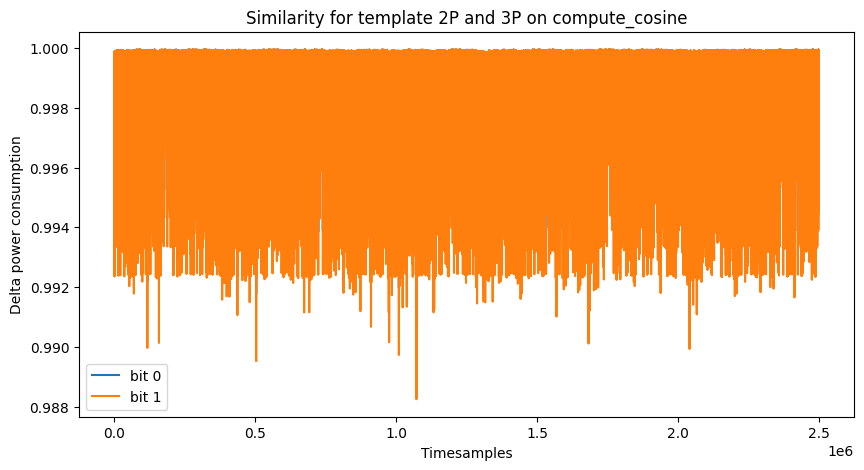

The correct keybit is: 1 0
The found keybit using compute_cosine is: 11
<function compute_mse at 0x7f9b2eda3e20> min


100%|██████████| 2498100/2498100 [1:03:41<00:00, 653.69it/s]


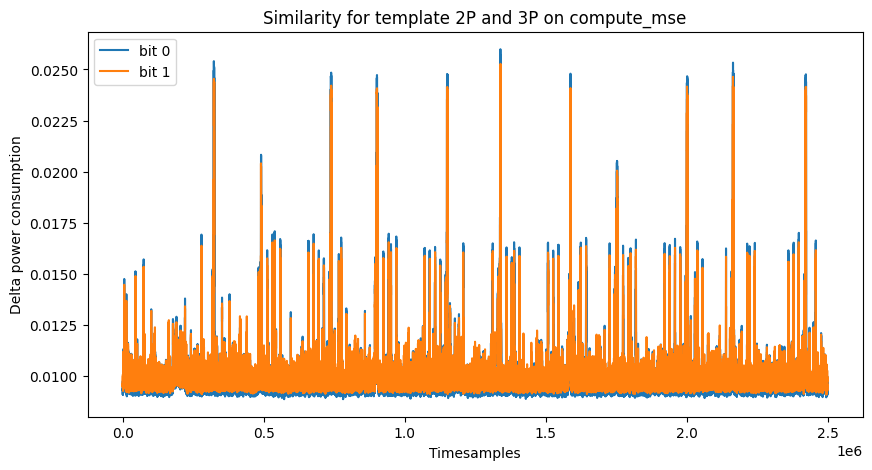

The correct keybit is: 1 0
The found keybit using compute_mse is: 10
<function compute_psnr at 0x7f9b2eda3b50> max


100%|██████████| 2498100/2498100 [1:03:37<00:00, 654.38it/s]


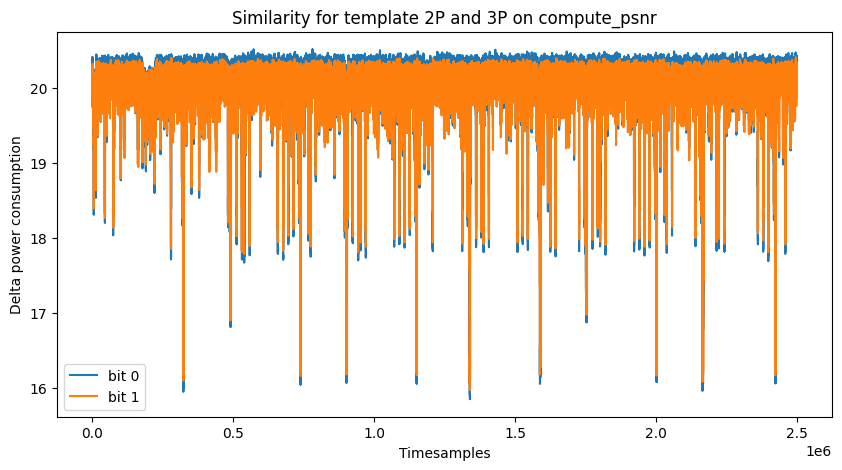

The correct keybit is: 1 0
The found keybit using compute_psnr is: 10
<function compute_cosine at 0x7f9b2eda3c70> max


100%|██████████| 2498100/2498100 [1:33:41<00:00, 444.38it/s]


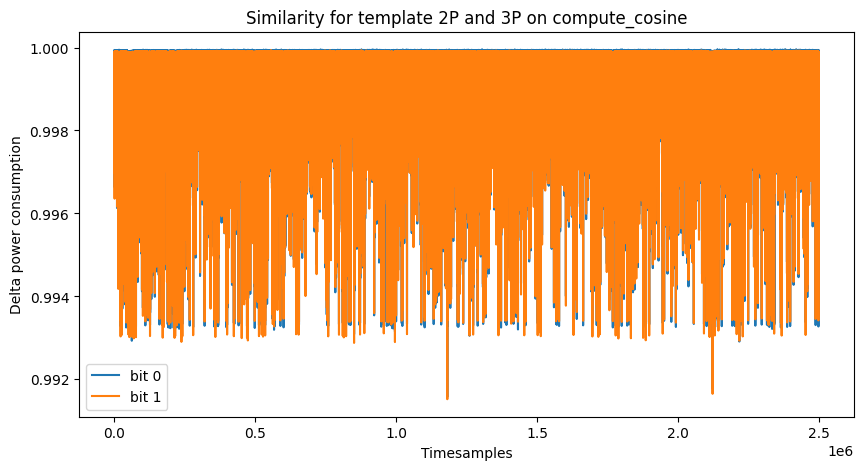

The correct keybit is: 1 1
The found keybit using compute_cosine is: 10
<function compute_mse at 0x7f9b2eda3e20> min


100%|██████████| 2498100/2498100 [1:04:39<00:00, 643.98it/s]


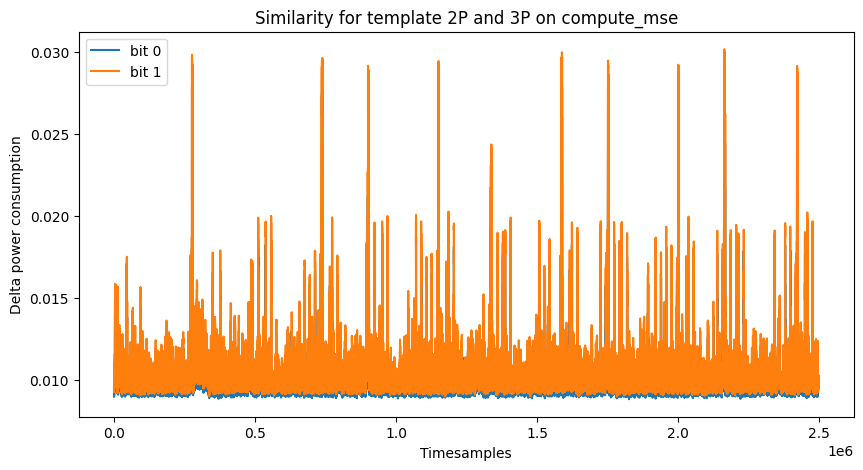

The correct keybit is: 1 1
The found keybit using compute_mse is: 10
<function compute_psnr at 0x7f9b2eda3b50> max


100%|██████████| 2498100/2498100 [57:27<00:00, 724.55it/s] 


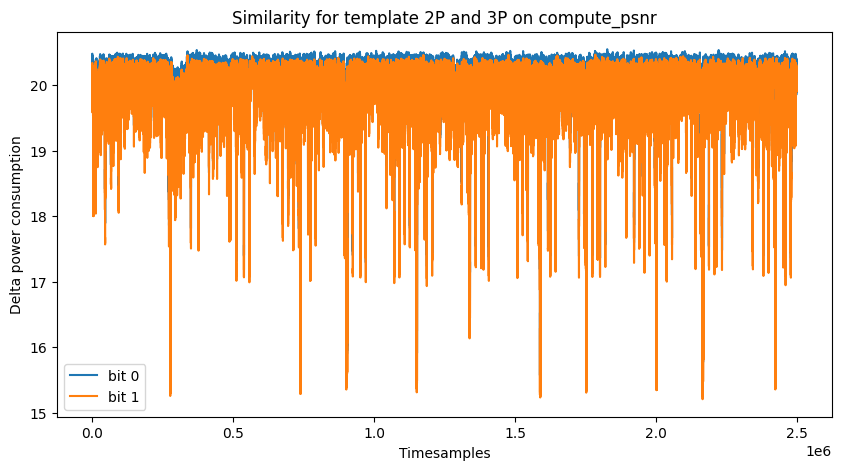

The correct keybit is: 1 1
The found keybit using compute_psnr is: 10


In [11]:
similarity_methods = [compute_cosine, compute_mse, compute_psnr]

## Add artificial noise here
for correct_keybit, single_trace_leakage in enumerate([single_trace_leakage_sc2, single_trace_leakage_sc3]):

    target_trace = single_trace_leakage[0]
    template_trace0 = single_trace_leakage[1]
    template_trace1 = single_trace_leakage[2]
    for method in similarity_methods:       
        if method.__name__ in ["compute_mse", "compute_distance_lpips"]:
                sign = "min"
        else:
                sign = "max"

        print(method, sign)

        comparison_0 = pattern_match(target_trace, template_trace0, method, poi_start, poi_end, step=step_size)
        comparison_1 = pattern_match(target_trace, template_trace1, method, poi_start, poi_end, step=step_size)

        plot_similarity(comparison_0, comparison_1, correct_keybit, similarity_function=method, leakage = "horizontal")
        keybit_guess = determine_keybit(comparison_0, comparison_1, sign=sign) 

        print("The correct keybit is: 1", correct_keybit)
        print("The found keybit using {} is: 1{}".format(method.__name__, keybit_guess))

        np.savez("./analysis/similarity_ota2_horizontal_sc1{}_{}".format(correct_keybit, method.__name__),  comparison_0 = comparison_0, comparison_1 = comparison_1)
